<a href="https://colab.research.google.com/github/Devan007-NJ/breast-cancer-diagnosis/blob/main/MLProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**BREAST CANCER DIAGNOSIS USING MACHINE LEARNING**


##**UPLOADING DATA AND IMPORTING LIBRARIES**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
#imported necessary python libraries

sns.set_theme(style="whitegrid")

In [ ]:
#importing dataset from kaggle
df=pd.read_csv('data.csv')


In [ ]:
df.info() #reading type data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
df.describe() #statsitcal analysis of data

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


##**DATA PREPROCESSING**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
df.shape

(569, 33)

In [ ]:
df.isnull().sum().sum()

np.int64(569)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
df.drop("Unnamed: 32", axis=1, inplace=True)

In [ ]:
df.isnull().sum().sum()

np.int64(0)

duplicates are deleted

In [ ]:
df = df.drop(columns=['id']) #id doesnt carry any signal

In [ ]:
#encoding the diagnosis
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

In [ ]:
df.columns = df.columns.str.replace(' ', '_')

creating X and Y data


In [ ]:
X=df.drop(columns="diagnosis")
y=df["diagnosis"]

##SKEWNESS IN THE DATA

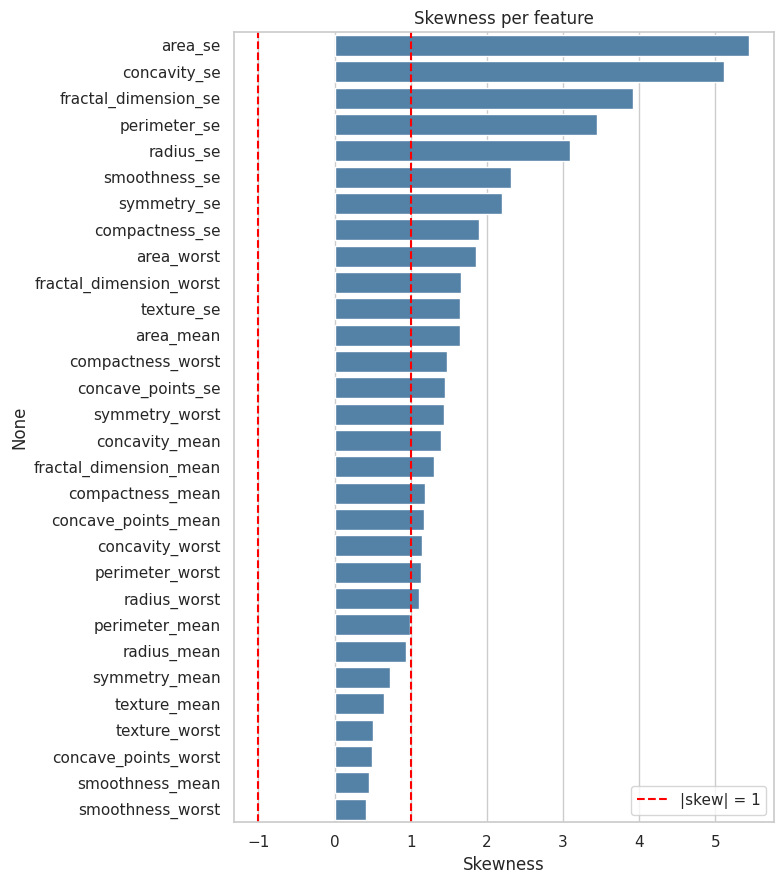

22 features with |skew| > 1


In [ ]:
skew =X.skew().sort_values(ascending=False)

plt.figure(figsize=(8, 9))
sns.barplot(x=skew.values, y=skew.index, color="steelblue")
plt.axvline(1, color="red", ls="--", label="|skew| = 1")
plt.axvline(-1, color="red", ls="--")
plt.title("Skewness per feature")
plt.xlabel("Skewness"); plt.legend()
plt.tight_layout(); plt.show()

skewed_cols = skew[skew.abs() > 1].index.tolist()
print(f"{len(skewed_cols)} features with |skew| > 1")

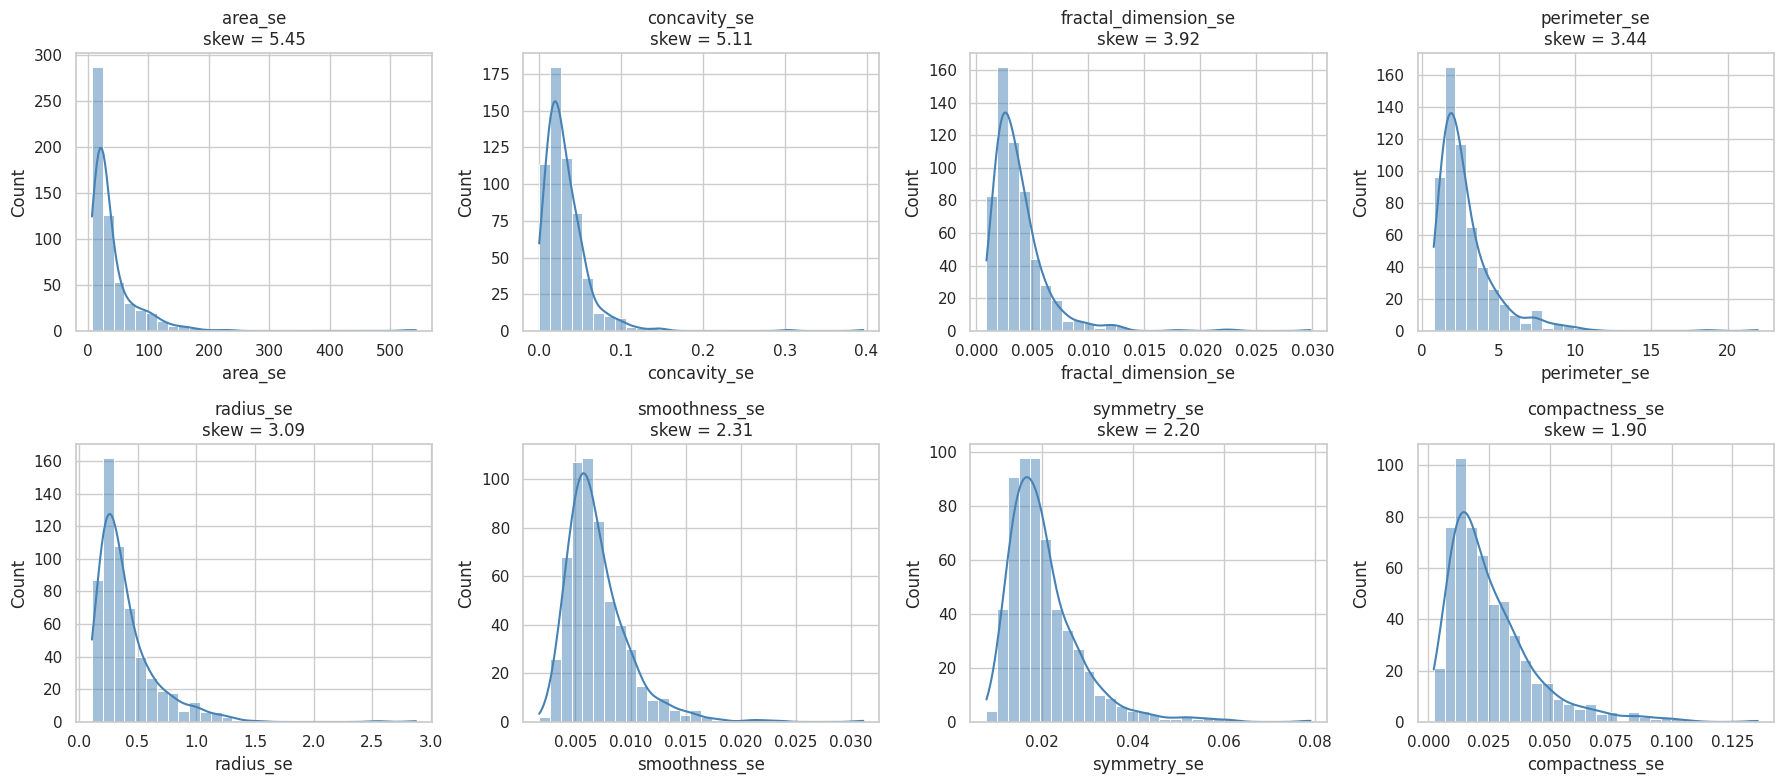

In [ ]:
top_skewed = skew.abs().sort_values(ascending=False).head(8).index

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), top_skewed):
    sns.histplot(X[col], kde=True, bins=30, ax=ax, color="steelblue")
    ax.set_title(f"{col}\nskew = {X[col].skew():.2f}")
plt.tight_layout(); plt.show()

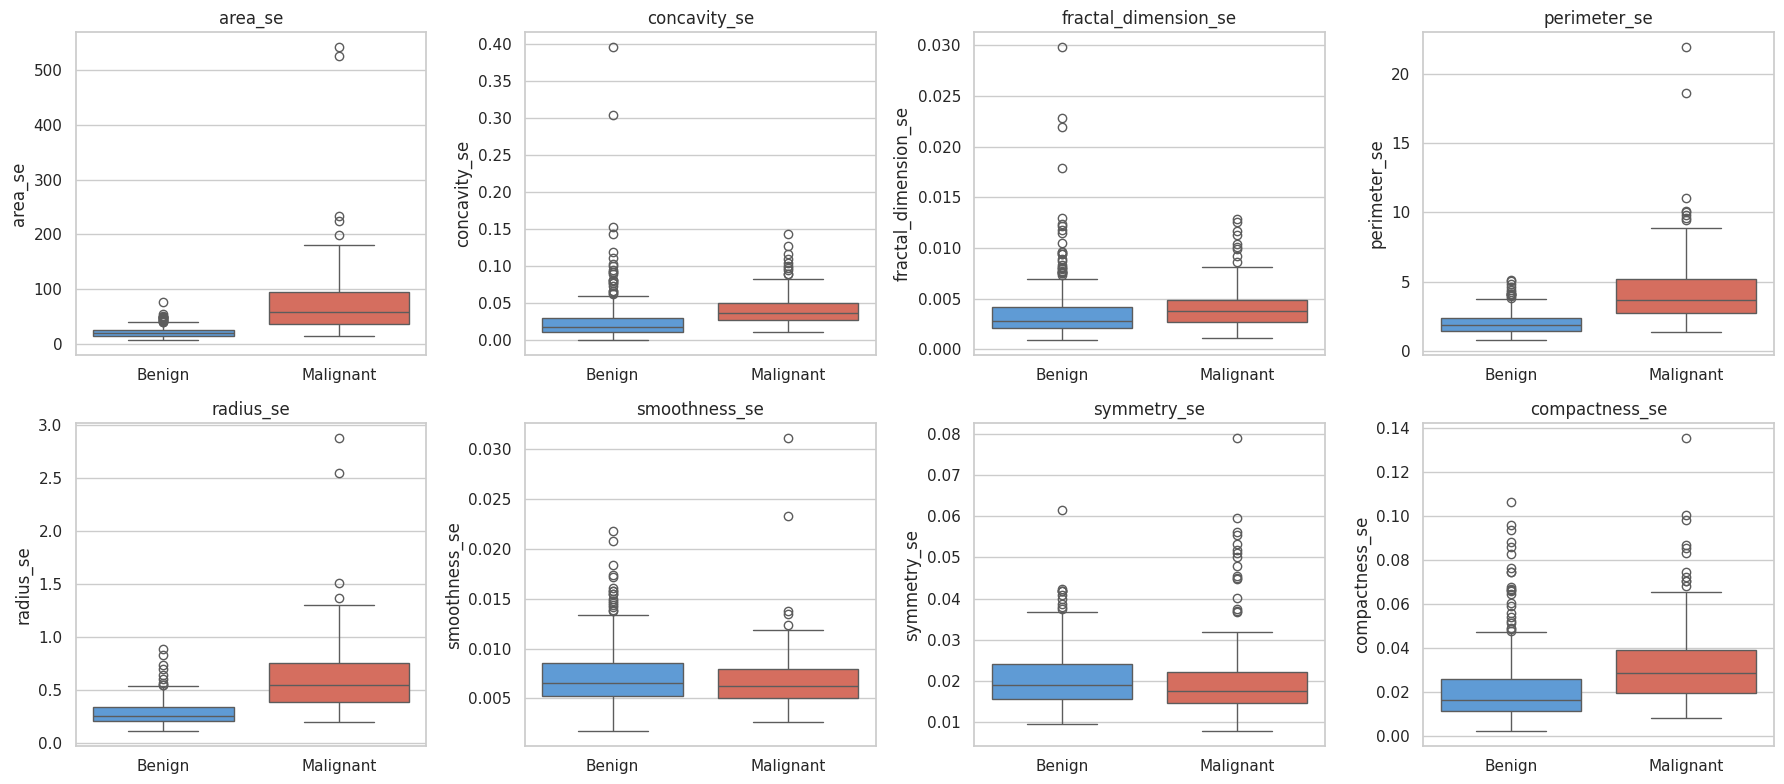

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), top_skewed):
    sns.boxplot(x=y, y=X[col], hue=y, ax=ax, palette=["#4C9BE8", "#E8604C"], legend=False)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Benign", "Malignant"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout(); plt.show()

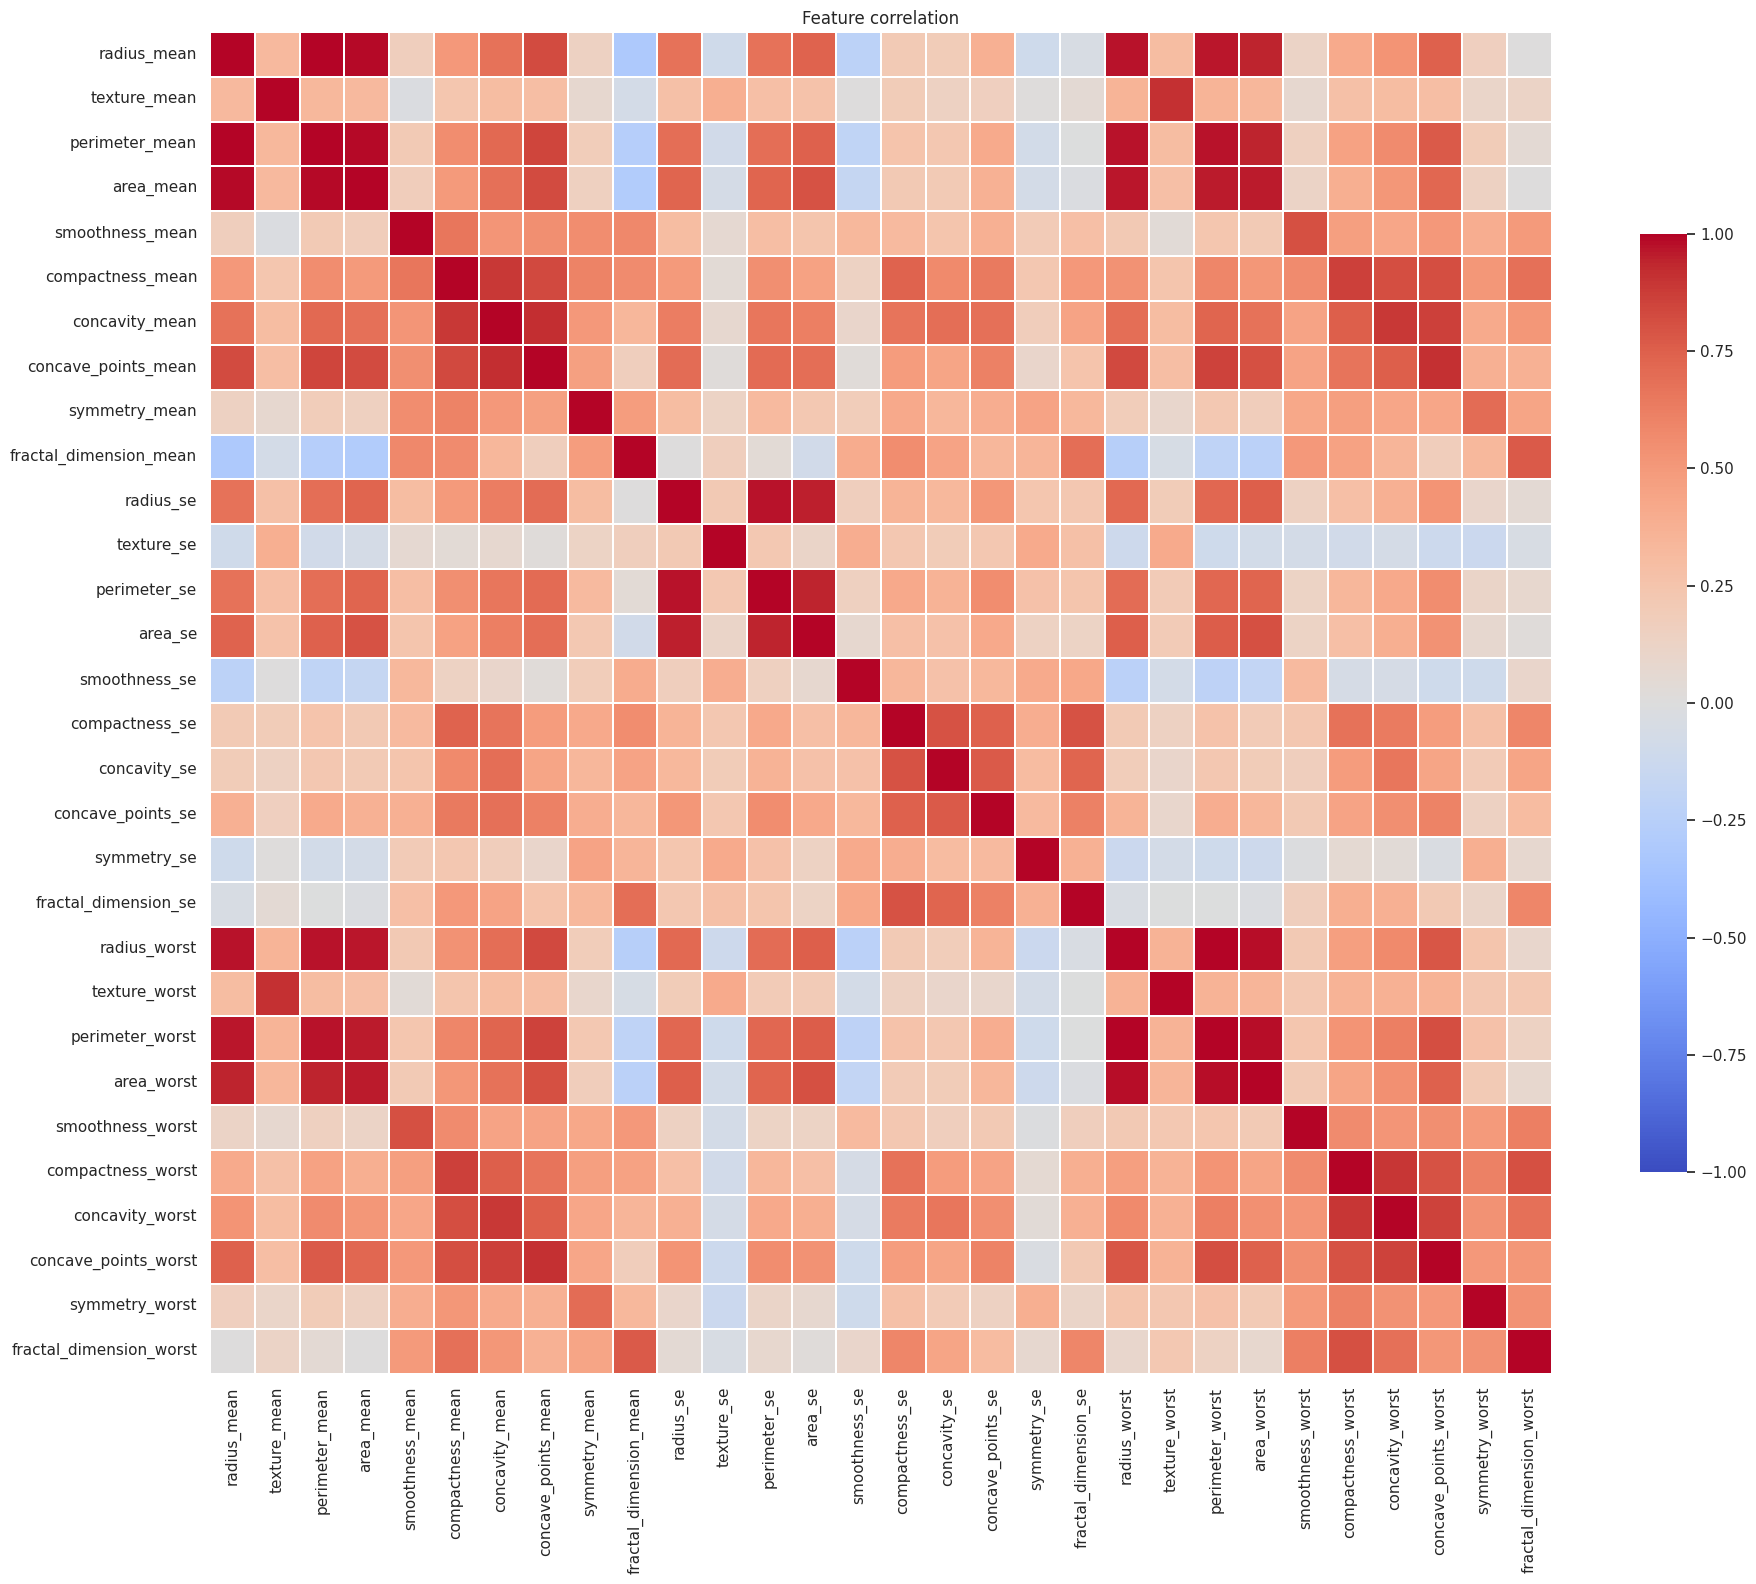

In [ ]:
corr = X.corr()

plt.figure(figsize=(20, 16))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Feature correlation")
plt.tight_layout(); plt.show()

In [ ]:
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = (upper.stack()
              .rename("abs_corr")
              .reset_index()
              .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
              .sort_values("abs_corr", ascending=False))

high = pairs[pairs["abs_corr"] > 0.9]
print(f"{len(high)} pairs with |r| > 0.9")
high.head(15)

21 pairs with |r| > 0.9


,feature_1,feature_2,abs_corr
1,radius_mean,perimeter_mean,0.997855
391,radius_worst,perimeter_worst,0.993708
2,radius_mean,area_mean,0.987357
57,perimeter_mean,area_mean,0.986507
392,radius_worst,area_worst,0.984015
407,perimeter_worst,area_worst,0.977578
246,radius_se,perimeter_se,0.972794
76,perimeter_mean,perimeter_worst,0.970387
19,radius_mean,radius_worst,0.969539
74,perimeter_mean,radius_worst,0.969476


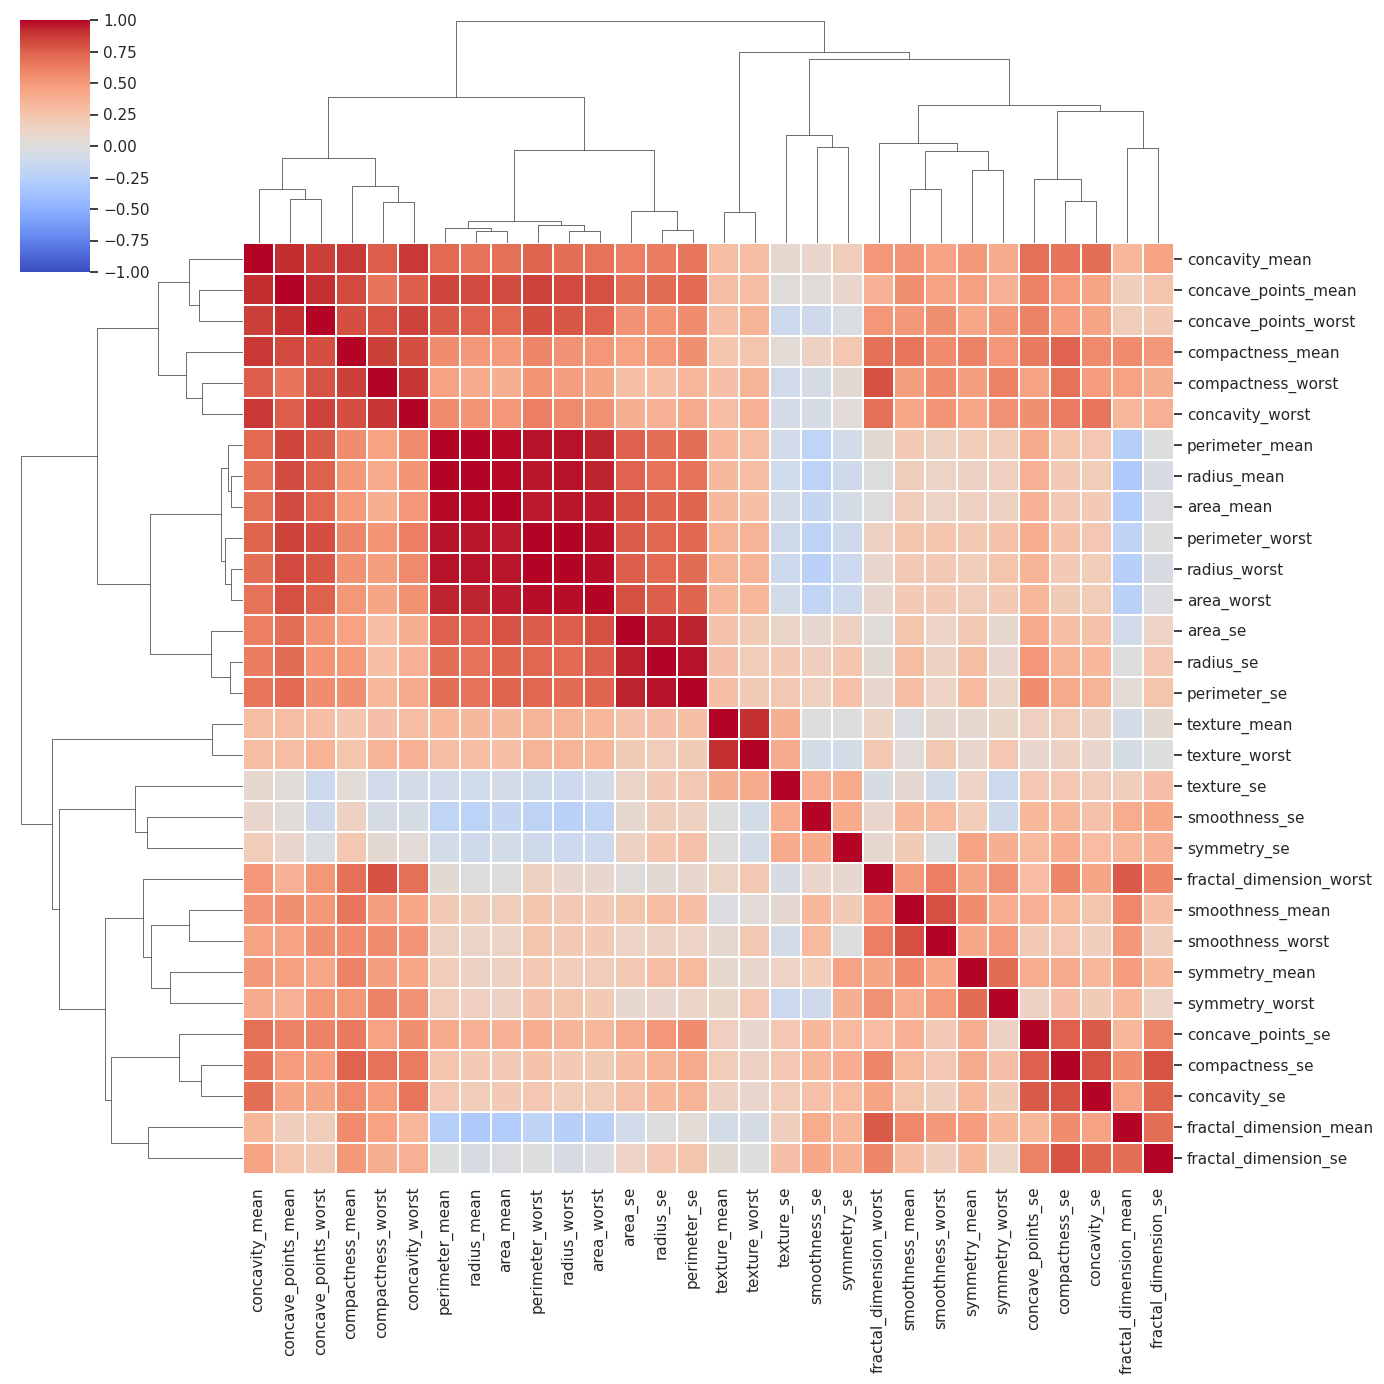

In [ ]:
sns.clustermap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
               figsize=(14, 14), linewidths=0.2)
plt.show()

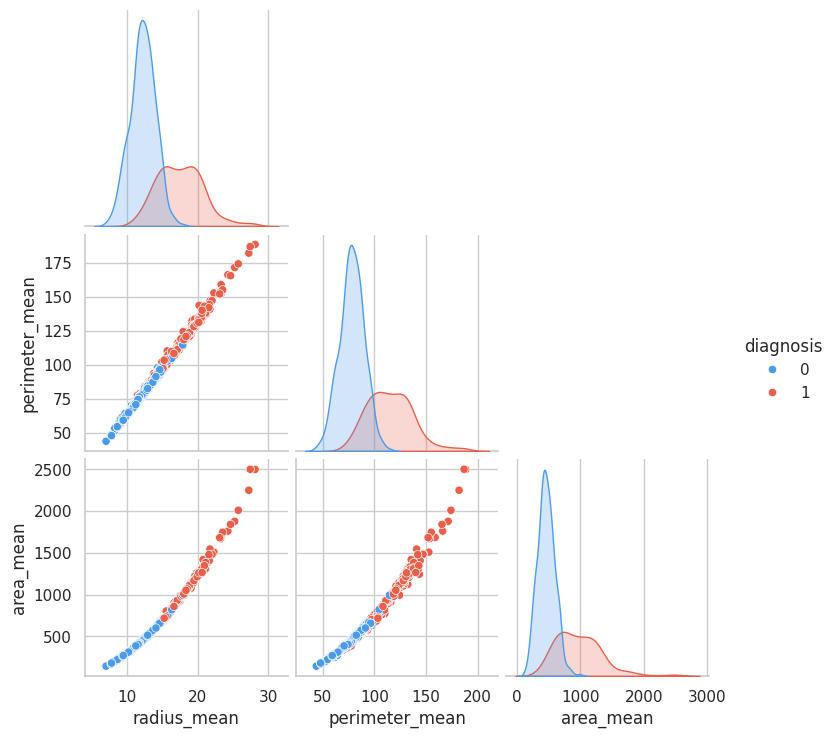

In [ ]:
sns.pairplot(df[["radius_mean", "perimeter_mean", "area_mean", "diagnosis"]],
             hue="diagnosis", palette=["#4C9BE8", "#E8604C"], corner=True)
plt.show()

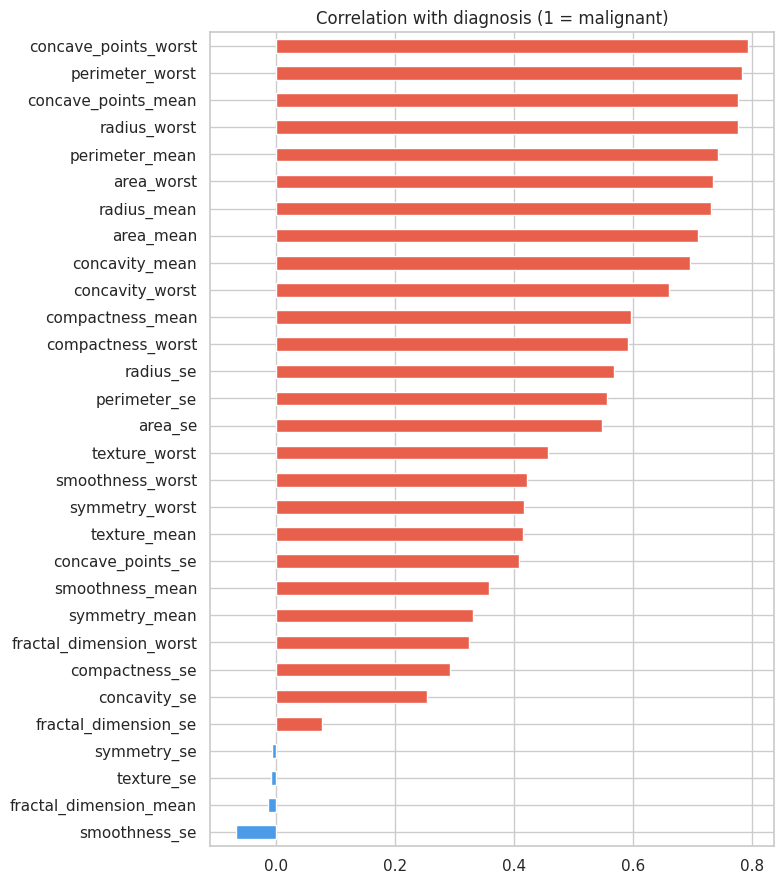

In [ ]:
target_corr = df.corr()["diagnosis"].drop("diagnosis").sort_values()

plt.figure(figsize=(8, 9))
target_corr.plot.barh(color=np.where(target_corr > 0, "#E8604C", "#4C9BE8"))
plt.title("Correlation with diagnosis (1 = malignant)")
plt.tight_layout(); plt.show()

##**FURTHER PREPROCESSING**

In [ ]:
#log transform and dropping correlated features
# Log-transform skewed features (log1p is safe for zeros)
X_log = X.copy()
X_log[skewed_cols] = np.log1p(X_log[skewed_cols])

# Drop one of each highly correlated pair, using the log-transformed data
corr_log = X_log.corr().abs()
upper_log = corr_log.where(np.triu(np.ones(corr_log.shape, dtype=bool), k=1))
to_drop = [c for c in upper_log.columns if (upper_log[c] > 0.9).any()]

X_reduced = X_log.drop(columns=to_drop)
print(f"Dropped {len(to_drop)} features: {to_drop}")
print(f"Remaining: {X_reduced.shape[1]} features")

Dropped 11 features: ['perimeter_mean', 'area_mean', 'concave_points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concavity_worst', 'concave_points_worst']
Remaining: 19 features


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),      columns=X_test.columns,  index=X_test.index)

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)
print("Train class ratio:", y_train.mean().round(3), "| Test class ratio:", y_test.mean().round(3))

Train: (455, 19) | Test: (114, 19)
Train class ratio: 0.374 | Test class ratio: 0.368


##**Verification of data cleaning**

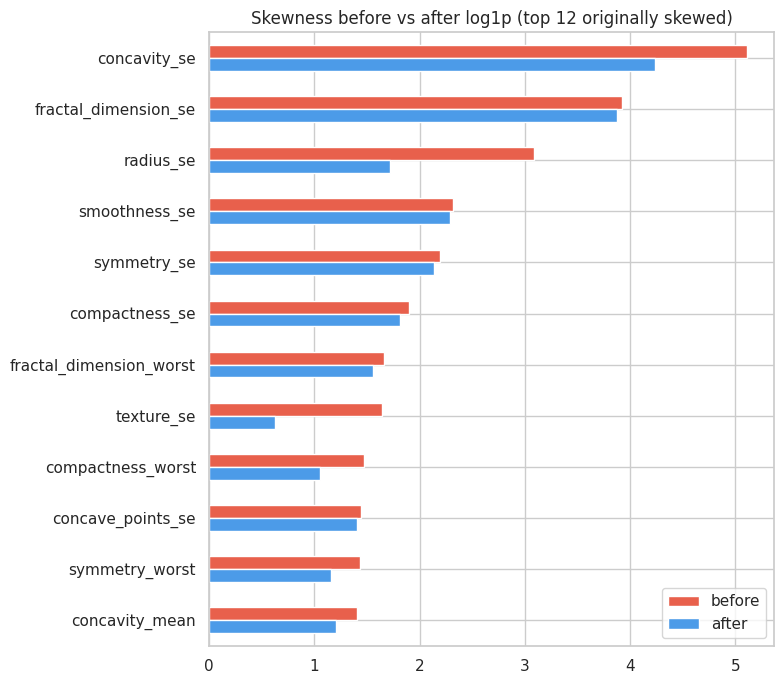

In [ ]:
skew_after = X_reduced.skew()
comp = pd.DataFrame({"before": X.skew(), "after": skew_after}).dropna()
comp = comp.reindex(comp["before"].abs().sort_values(ascending=False).index).head(12)

comp.plot.barh(figsize=(8, 7), color=["#E8604C", "#4C9BE8"])
plt.gca().invert_yaxis()
plt.title("Skewness before vs after log1p (top 12 originally skewed)")
plt.tight_layout(); plt.show()

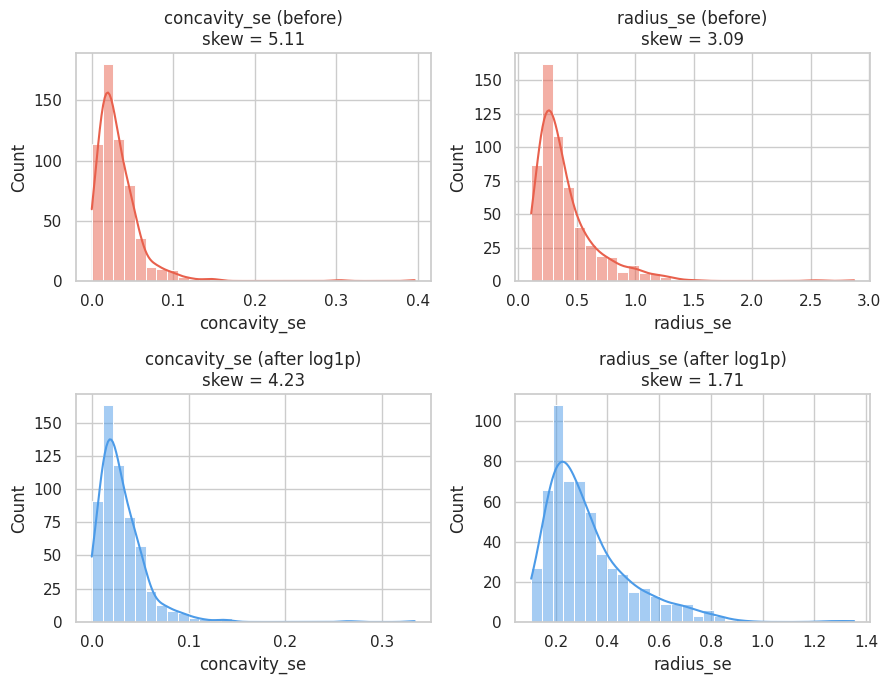

In [ ]:
cols = [c for c in ["area_se", "concavity_se", "perimeter_se", "radius_se"] if c in X_reduced.columns]
fig, axes = plt.subplots(2, len(cols), figsize=(4.5 * len(cols), 7))
for i, col in enumerate(cols):
    sns.histplot(X[col], kde=True, ax=axes[0, i], color="#E8604C", bins=30)
    axes[0, i].set_title(f"{col} (before)\nskew = {X[col].skew():.2f}")
    sns.histplot(X_reduced[col], kde=True, ax=axes[1, i], color="#4C9BE8", bins=30)
    axes[1, i].set_title(f"{col} (after log1p)\nskew = {X_reduced[col].skew():.2f}")
plt.tight_layout(); plt.show()

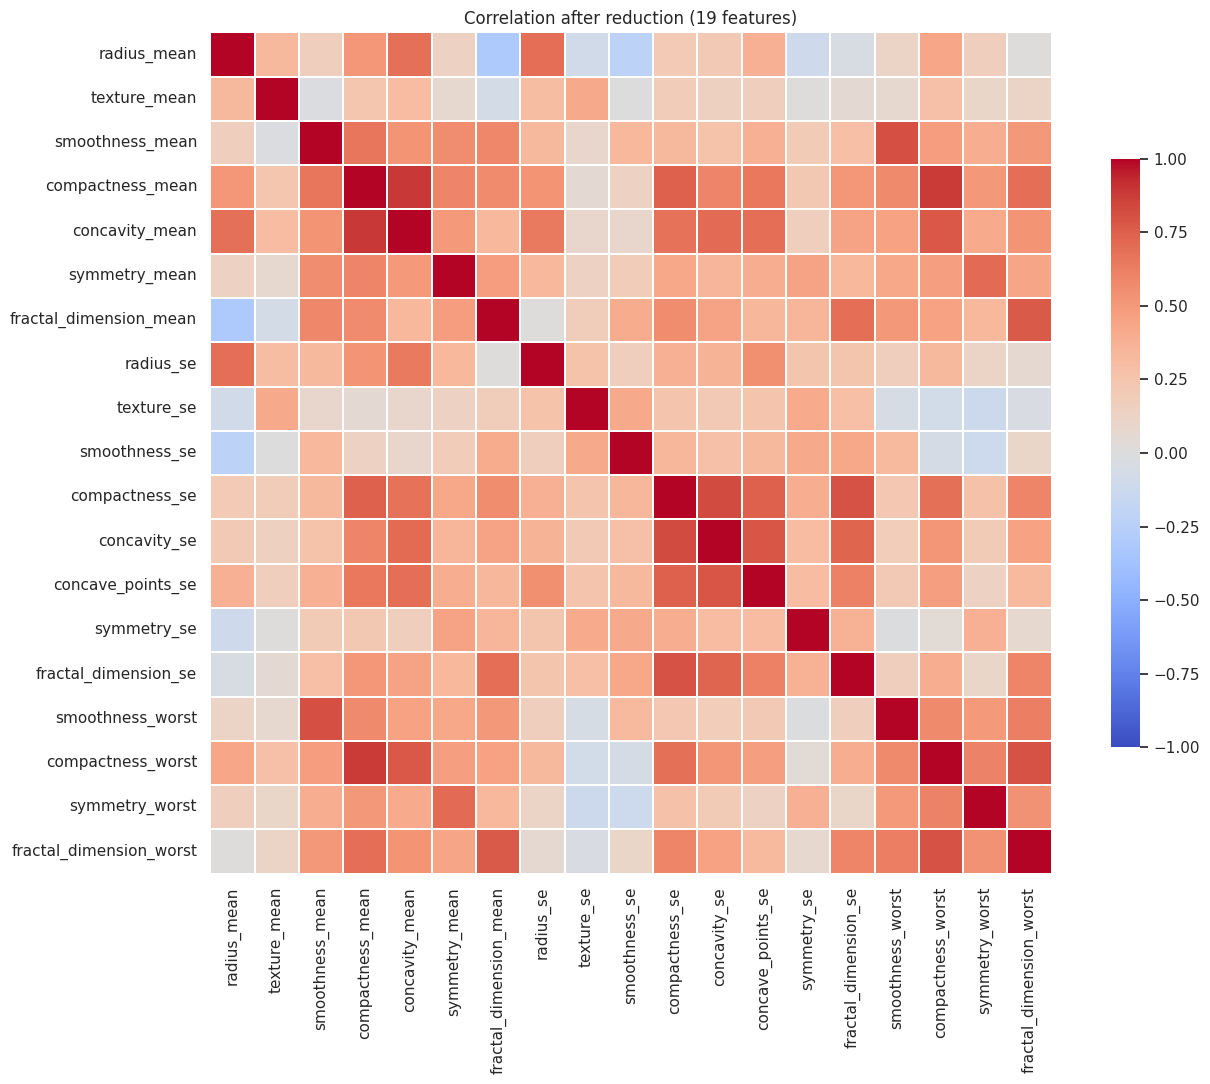

Max remaining |r|: 0.887


In [ ]:
corr_after = X_reduced.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr_after, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title(f"Correlation after reduction ({X_reduced.shape[1]} features)")
plt.tight_layout(); plt.show()

# Highest remaining correlation between two different features
off_diag = corr_after.abs().values.copy()
np.fill_diagonal(off_diag, 0)
print("Max remaining |r|:", off_diag.max().round(3))